# Grover with noise

**Question.** Real quantum computers make small errors on every gate. How much does that hurt Grover's algorithm?

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
from qiskit import transpile
from qiskit_aer import AerSimulator

%run grover_core.ipynb   # loads grover, optimal_iterations, theoretical_success, success_rate, depolarizing_noise_model

os.makedirs("figures", exist_ok=True)

N_QUBITS = 3
MARKED = "101"
K = 1
N = 2 ** N_QUBITS
R_OPT = optimal_iterations(N_QUBITS, K)
R_MAX = 8
SHOTS = 4096
NOISE_LEVELS = [0.0, 0.001, 0.005, 0.01, 0.02, 0.05]   # CNOT error probability p2 (1-qubit gates: p2 / 10)

rng = np.random.default_rng(7)   # gives every run its own seed: reproducible, but independent runs
print(f"n = {N_QUBITS}, marked = {MARKED}, ideal optimal r = {R_OPT}, random guess k/N = {K / N:.3f}")

n = 3, marked = 101, ideal optimal r = 2, random guess k/N = 0.125


## Transpile once to the noise model's gates

The noise model only knows the gates `rz, sx, x, cx`. We rewrite (transpile) each Grover circuit into these gates **once**, and then run exactly the same circuit at every noise level.
That way, the only thing that changes between the curves is the noise.

The table shows how fast the circuit grows: each Grover round adds a fixed number of gates, and in particular CNOTs (the noisiest gate).

In [7]:
rs = list(range(R_MAX + 1))
circuits = {}
print(" r | CNOTs | 1-qubit gates (sx, x) | depth")
for r in rs:
    qc_t = transpile(grover(N_QUBITS, MARKED, r), basis_gates=NOISE_BASIS_GATES,
                     optimization_level=1, seed_transpiler=1)
    circuits[r] = qc_t
    ops = qc_t.count_ops()
    print(f"{r:2d} | {ops.get('cx', 0):5d} | {ops.get('sx', 0) + ops.get('x', 0):21d} | {qc_t.depth():5d}")

 r | CNOTs | 1-qubit gates (sx, x) | depth
 0 |     0 |                     3 |     4
 1 |    12 |                     9 |    30
 2 |    24 |                    15 |    56
 3 |    36 |                    21 |    82
 4 |    48 |                    27 |   108
 5 |    60 |                    33 |   134
 6 |    72 |                    39 |   160
 7 |    84 |                    45 |   186
 8 |    96 |                    51 |   212


## Run every (noise level, r) combination

For each noise level and each $r$ we (a) sample 4096 shots and (b) compute the exact success probability with the density-matrix simulator.
For (b) the final measurements are removed and replaced by `save_probabilities()`, which asks the simulator to return the exact probability of every bitstring.

In [8]:
MARKED_INDEX = int(MARKED, 2)   # position of '101' in the list of probabilities

results, exact = {}, {}
for p2 in NOISE_LEVELS:
    nm = depolarizing_noise_model(p2)
    sim = AerSimulator(noise_model=nm)
    sim_exact = AerSimulator(method="density_matrix", noise_model=nm)
    results[p2], exact[p2] = [], []
    for r in rs:
        seed = int(rng.integers(2**31))
        counts = sim.run(circuits[r], shots=SHOTS, seed_simulator=seed).result().get_counts()
        results[p2].append(success_rate(counts, MARKED, SHOTS))

        qc_exact = circuits[r].copy()
        qc_exact.remove_final_measurements()
        qc_exact.save_probabilities()
        exact[p2].append(sim_exact.run(qc_exact).result().data()["probabilities"][MARKED_INDEX])

print("sampled (4096 shots) / exact")
print(" r | theory | " + " | ".join(f"p2={p2:<5}     " for p2 in NOISE_LEVELS))
for i, r in enumerate(rs):
    print(f"{r:2d} | {theoretical_success(N_QUBITS, r, K):.3f}  | "
          + " | ".join(f"{results[p2][i]:.3f} / {exact[p2][i]:.3f}" for p2 in NOISE_LEVELS))

sampled (4096 shots) / exact
 r | theory | p2=0.0        | p2=0.001      | p2=0.005      | p2=0.01       | p2=0.02       | p2=0.05      
 0 | 0.125  | 0.120 / 0.125 | 0.127 / 0.125 | 0.133 / 0.125 | 0.130 / 0.125 | 0.132 / 0.125 | 0.130 / 0.125
 1 | 0.781  | 0.788 / 0.781 | 0.772 / 0.774 | 0.741 / 0.743 | 0.708 / 0.708 | 0.644 / 0.642 | 0.491 / 0.483
 2 | 0.945  | 0.941 / 0.945 | 0.927 / 0.927 | 0.849 / 0.856 | 0.772 / 0.777 | 0.627 / 0.642 | 0.383 / 0.380
 3 | 0.330  | 0.326 / 0.330 | 0.327 / 0.324 | 0.309 / 0.300 | 0.275 / 0.275 | 0.244 / 0.234 | 0.174 / 0.167
 4 | 0.012  | 0.014 / 0.012 | 0.015 / 0.018 | 0.038 / 0.039 | 0.059 / 0.059 | 0.091 / 0.088 | 0.118 / 0.120
 5 | 0.548  | 0.552 / 0.548 | 0.536 / 0.525 | 0.437 / 0.445 | 0.369 / 0.366 | 0.253 / 0.263 | 0.152 / 0.150
 6 | 1.000  | 1.000 / 1.000 | 0.944 / 0.942 | 0.764 / 0.747 | 0.568 / 0.567 | 0.349 / 0.347 | 0.161 / 0.153
 7 | 0.577  | 0.578 / 0.577 | 0.537 / 0.543 | 0.434 / 0.431 | 0.333 / 0.333 | 0.218 / 0.221 | 0.129 / 0.134

In [9]:
print("noise p2 | best r | exact success at best r | r=1    | r=2    | r=6")
for p2 in NOISE_LEVELS:
    e = exact[p2]
    best = int(np.argmax(np.round(e, 4)))
    ties = [r for r in rs if round(e[r], 4) == round(e[best], 4)]
    best_txt = " = ".join(str(r) for r in ties)
    print(f"{p2:8.3f} | {best_txt:>6} | {e[best]:23.4f} | {e[1]:.4f} | {e[2]:.4f} | {e[6]:.4f}")

noise p2 | best r | exact success at best r | r=1    | r=2    | r=6
   0.000 |      6 |                  0.9998 | 0.7812 | 0.9453 | 0.9998
   0.001 |      6 |                  0.9421 | 0.7735 | 0.9267 | 0.9421
   0.005 |      2 |                  0.8563 | 0.7435 | 0.8563 | 0.7469
   0.010 |      2 |                  0.7766 | 0.7077 | 0.7766 | 0.5667
   0.020 |      1 |                  0.6418 | 0.6418 | 0.6417 | 0.3473
   0.050 |      1 |                  0.4832 | 0.4832 | 0.3798 | 0.1528


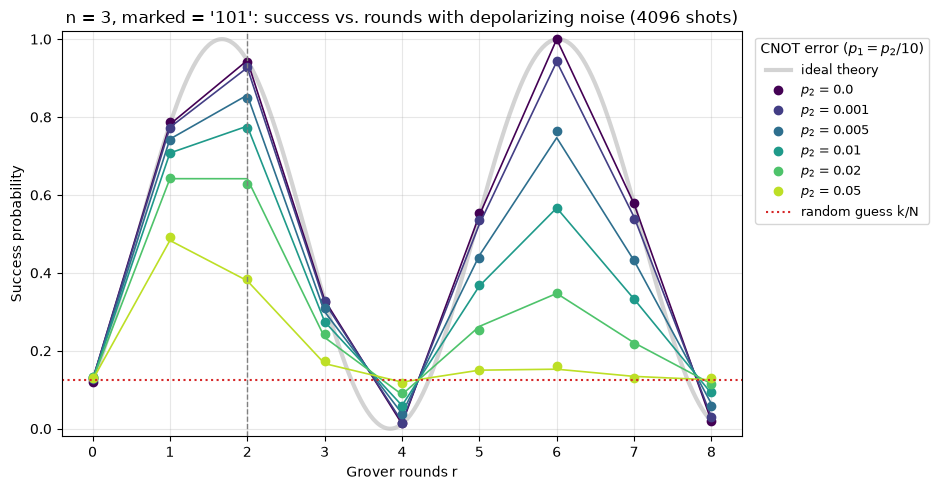

In [10]:
fine_r = np.linspace(0, R_MAX, 400)
theta = np.arcsin(np.sqrt(K / N))
colors = plt.cm.viridis(np.linspace(0, 0.9, len(NOISE_LEVELS)))

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(fine_r, np.sin((2 * fine_r + 1) * theta) ** 2, "-", color="lightgray", linewidth=3, label="ideal theory", zorder=0)
for p2, c in zip(NOISE_LEVELS, colors):
    ax.plot(rs, exact[p2], "-", color=c, linewidth=1.2)
    ax.plot(rs, results[p2], "o", color=c, label=f"$p_2$ = {p2}")
ax.axhline(K / N, color="tab:red", linestyle=":", label="random guess k/N")
ax.axvline(R_OPT, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Grover rounds r")
ax.set_ylabel("Success probability")
ax.set_title(f"n = 3, marked = '{MARKED}': success vs. rounds with depolarizing noise ({SHOTS} shots)")
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.3)
ax.legend(title="CNOT error ($p_1 = p_2/10$)", loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout()
plt.savefig("figures/fig_noise_success_vs_rounds.png", dpi=200, bbox_inches="tight")
plt.show()